# 01 · Raw data ingestion

Create a trustworthy inventory of the downloaded audio **without changing a single recording**.

**Input:** `data/raw/mini_speech_commands/<word>/*.wav`  
**Output:** `data/processed/baseline_v1/01_ingested.jsonl`

The provisional keyword is **stop**. The seven remaining commands are negative speech; they are not background silence.

## 1. Locate the experiment

Only paths and configuration are initialized here.

In [1]:
from pathlib import Path
from collections import Counter
import hashlib, json
import matplotlib.pyplot as plt
from IPython import get_ipython
get_ipython().run_line_magic("matplotlib", "inline")

root = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "configs/preprocessing.json").exists())
cfg = json.loads((root / "configs/preprocessing.json").read_text())
source = root / cfg["source_dir"]
output = root / "data/processed" / cfg["run_name"]
output.mkdir(parents=True, exist_ok=True)

In [2]:
words = {"down", "go", "left", "no", "right", "stop", "up", "yes"}
wav_paths = sorted(source.glob("*/*.wav"))
if not wav_paths:
    raise FileNotFoundError(f"No WAV files found under {source}")
print(f"Found {len(wav_paths):,} WAV files in {source.relative_to(root)}")

Found 8,000 WAV files in data/raw/mini_speech_commands


## 2. Fingerprint and describe each source file

The filename prefix before `_nohash_` is the speaker identifier supplied by Speech Commands. Boundary fields stay empty because the corpus does not provide verified keyword timing.

### Math for the next code block — file fingerprint

For file bytes $b$, the code stores the deterministic digest

$$h=\operatorname{SHA256}(b).$$

Equal digests are used as an exact-integrity check. A hash is an identifier, not a numerical measure of acoustic similarity.

In [3]:
def sha256(path):
    digest = hashlib.sha256()
    with path.open("rb") as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()

In [4]:
def describe(path):
    word = path.parent.name
    if word not in words or "_nohash_" not in path.stem:
        raise ValueError(f"Unexpected source path: {path}")
    return {"id":f"{word}__{path.stem}", "raw_path":str(path.relative_to(root)),
            "raw_sha256":sha256(path), "word":word,
            "speaker_id":path.stem.split("_nohash_")[0],
            "is_keyword":int(word == cfg["keyword"]), "is_augmented":False,
            "source":"Google Mini Speech Commands", "license":"CC BY 4.0",
            "alignment_status":"missing", "keyword_start_seconds":None,
            "keyword_end_seconds":None}

In [5]:
rows = [describe(path) for path in wav_paths]
manifest = output / "01_ingested.jsonl"
with manifest.open("w") as stream:
    for row in rows:
        stream.write(json.dumps(row, allow_nan=False) + "\n")
print(f"Saved {len(rows):,} records → {manifest.relative_to(root)}")

Saved 8,000 records → data/processed/baseline_v1/01_ingested.jsonl


## 3. Check what was ingested

This is the first useful checkpoint: class balance, speaker coverage, and the exact schema passed to notebook 02.

### Math for the next code block — corpus counts

For word label $w$ and recording labels $y_i$, the class count is

$$n_w=\sum_{i=1}^{R}\mathbf{1}[y_i=w].$$

$R$ is the total number of recordings and $\mathbf{1}[\cdot]$ equals 1 when its condition is true. Unique-speaker coverage is the cardinality $|\{s_i\}|$ of the speaker-ID set.

In [6]:
counts = Counter(row["word"] for row in rows)
summary = {"recordings":len(rows),
           "speakers":len({row["speaker_id"] for row in rows}),
           "keyword_recordings":sum(row["is_keyword"] for row in rows),
           "missing_alignments":sum(row["alignment_status"] == "missing" for row in rows)}
display(summary)

{'recordings': 8000,
 'speakers': 1750,
 'keyword_recordings': 1000,
 'missing_alignments': 8000}

In [7]:
columns = ("id", "word", "speaker_id", "is_keyword", "alignment_status")
display([{column:row[column] for column in columns} for row in rows[:5]])

[{'id': 'down__004ae714_nohash_0',
  'word': 'down',
  'speaker_id': '004ae714',
  'is_keyword': 0,
  'alignment_status': 'missing'},
 {'id': 'down__00b01445_nohash_1',
  'word': 'down',
  'speaker_id': '00b01445',
  'is_keyword': 0,
  'alignment_status': 'missing'},
 {'id': 'down__00f0204f_nohash_0',
  'word': 'down',
  'speaker_id': '00f0204f',
  'is_keyword': 0,
  'alignment_status': 'missing'},
 {'id': 'down__0132a06d_nohash_1',
  'word': 'down',
  'speaker_id': '0132a06d',
  'is_keyword': 0,
  'alignment_status': 'missing'},
 {'id': 'down__0132a06d_nohash_4',
  'word': 'down',
  'speaker_id': '0132a06d',
  'is_keyword': 0,
  'alignment_status': 'missing'}]

## 4. Visual sanity check

Balanced word counts are expected in this mini corpus. They do not imply balanced speakers, acoustic conditions, or deployment scenarios.

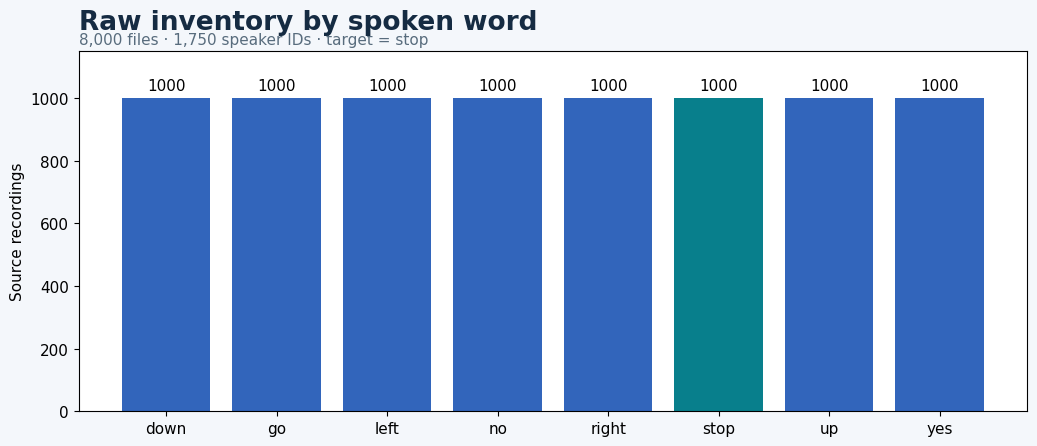

In [8]:
INK, BLUE, TEAL = "#152b42", "#3265bb", "#087f8c"
plt.rcParams.update({"figure.facecolor":"#f4f7fb", "axes.facecolor":"white", "font.size":11})
labels = sorted(counts); values = [counts[label] for label in labels]
fig, ax = plt.subplots(figsize=(10.5, 4.6))
bars = ax.bar(labels, values, color=[TEAL if label==cfg["keyword"] else BLUE for label in labels])
ax.bar_label(bars, padding=4); ax.set(ylabel="Source recordings", ylim=(0,max(values)*1.15))
ax.set_title("Raw inventory by spoken word", loc="left", fontsize=19, weight="bold", color=INK, pad=16)
ax.text(0,1.02,f"{len(rows):,} files · {summary['speakers']:,} speaker IDs · target = {cfg['keyword']}",
        transform=ax.transAxes,color="#586c7d")
fig.tight_layout(); figures=root/"reports/preprocessing"/cfg["run_name"]/"figures"; figures.mkdir(parents=True,exist_ok=True)
fig.savefig(figures/"01_raw_inventory.png",dpi=170,bbox_inches="tight"); fig.savefig(figures/"01_raw_inventory.svg",bbox_inches="tight"); plt.show()

## 5. Preserve source provenance

The archive hash identifies the exact local download. It is a local fingerprint, not publisher authentication.

In [9]:
archive = root / cfg["archive"]
provenance = {"archive":cfg["archive"],
              "archive_sha256":sha256(archive) if archive.exists() else None,
              "source_url":"https://storage.googleapis.com/download.tensorflow.org/data/mini_speech_commands.zip",
              "source_files":len(rows), "fingerprint_note":"Locally measured hashes"}
(output/"provenance.json").write_text(json.dumps(provenance,indent=2)+"\n")
(output/"config.json").write_text(json.dumps(cfg,indent=2)+"\n")
display(provenance)

{'archive': 'data/downloads/mini_speech_commands.zip',
 'archive_sha256': '49650f2341b26d886b46b3f4fb8fed59e30300b17550f1ee4a768b3106cf93a0',
 'source_url': 'https://storage.googleapis.com/download.tensorflow.org/data/mini_speech_commands.zip',
 'source_files': 8000,
 'fingerprint_note': 'Locally measured hashes'}

## What this stage proves

- The expected eight folders and 8,000 source WAV files are present.
- Each file has a reproducible hash and speaker identifier.
- Raw recordings were only read; no audio transformation happened.
- Word labels exist, but keyword boundaries and phonetic-state labels do not.

Continue with [02 · Data profiling](02_data_profiling.ipynb).